In [1]:
%matplotlib inline
from copy import deepcopy
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
plt.rcParams['figure.figsize'] = (16, 9)
plt.style.use('ggplot')

In [3]:
data = pd.read_csv('xclara.csv')
print(data.shape)
data.head()

(3000, 2)


,V1,V2
0,2.072345,-3.241693
1,17.936710,15.784810
2,1.083576,7.319176
3,11.120670,14.406780
4,23.711550,2.557729


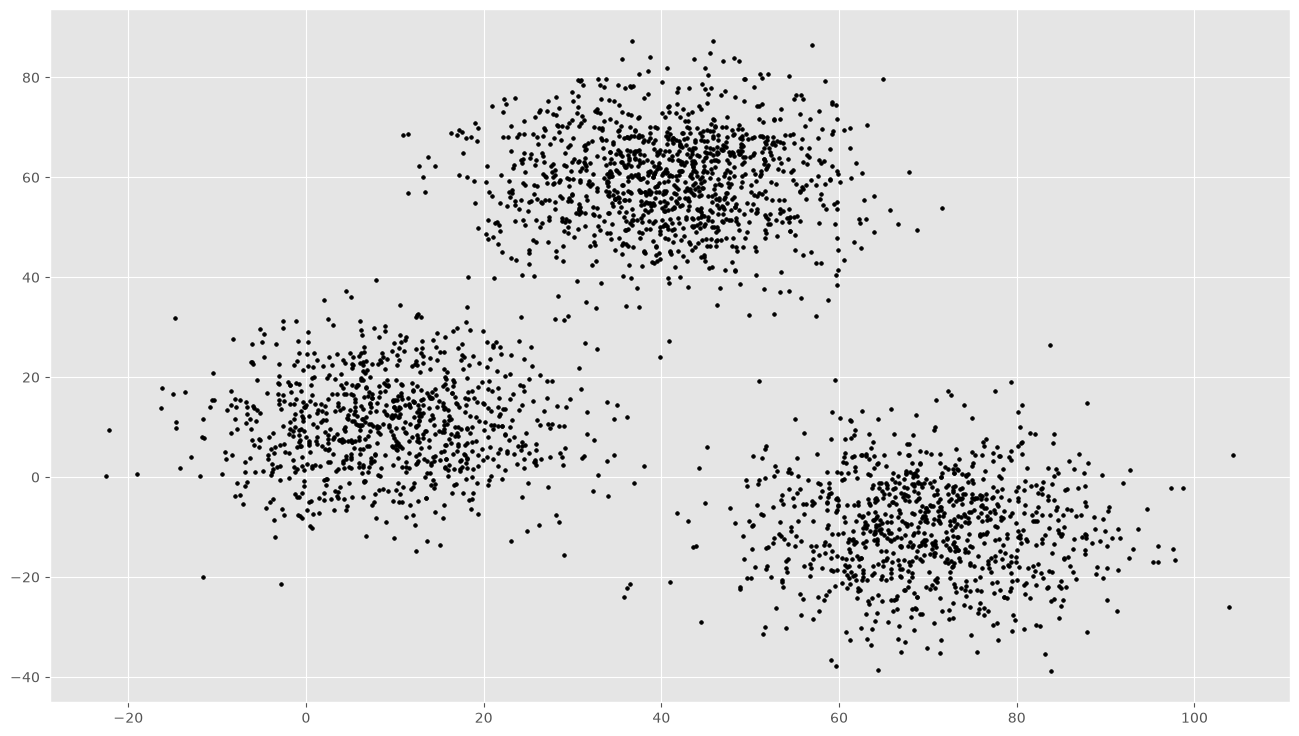

In [6]:
f1 = data['V1'].values
f2 = data['V2'].values
X = np.array(list(zip(f1, f2)))
plt.scatter(f1, f2, c='black', s=7)

In [7]:
def dist(a, b, ax=1):
    return np.linalg.norm(a - b, axis=ax)


In [10]:
k = 3
C_x = np.random.randint(0, np.max(X) - 20, size=k)
C_y = np.random.randint(0, np.max(X) - 20, size=k)
C = np.array(list(zip(C_x, C_y)), dtype=np.float32)
print(C)

[[20. 28.]
 [19.  5.]
 [63. 80.]]


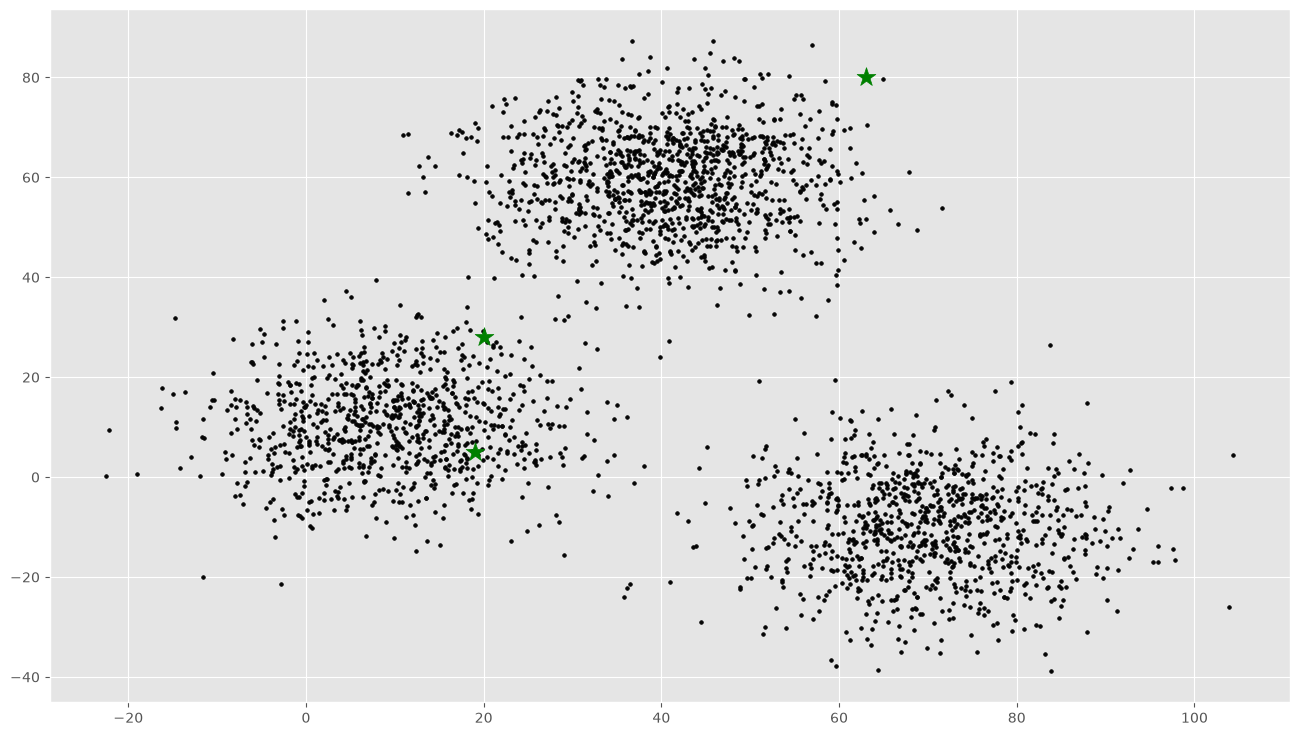

In [11]:
plt.scatter(f1, f2, c='#050505', s=7)
plt.scatter(C_x, C_y, marker='*', s=200, c='g')

In [13]:
C_old = np.zeros(C.shape)
clusters = np.zeros(len(X))
error = dist(C_old, C, None)

while error != 0:
    for i in range(len(X)):
        distances = dist(X[i], C)
        cluster = np.argmin(distances)
        clusters[i] = cluster
        
    C_old = deepcopy(C)
    
    for i in range(k):
        points = [X[j] for j in range(len(X)) if clusters[j] == i]
        C[i] = np.mean(points, axis=0)
    
    error = dist(C_old, C, None)
    

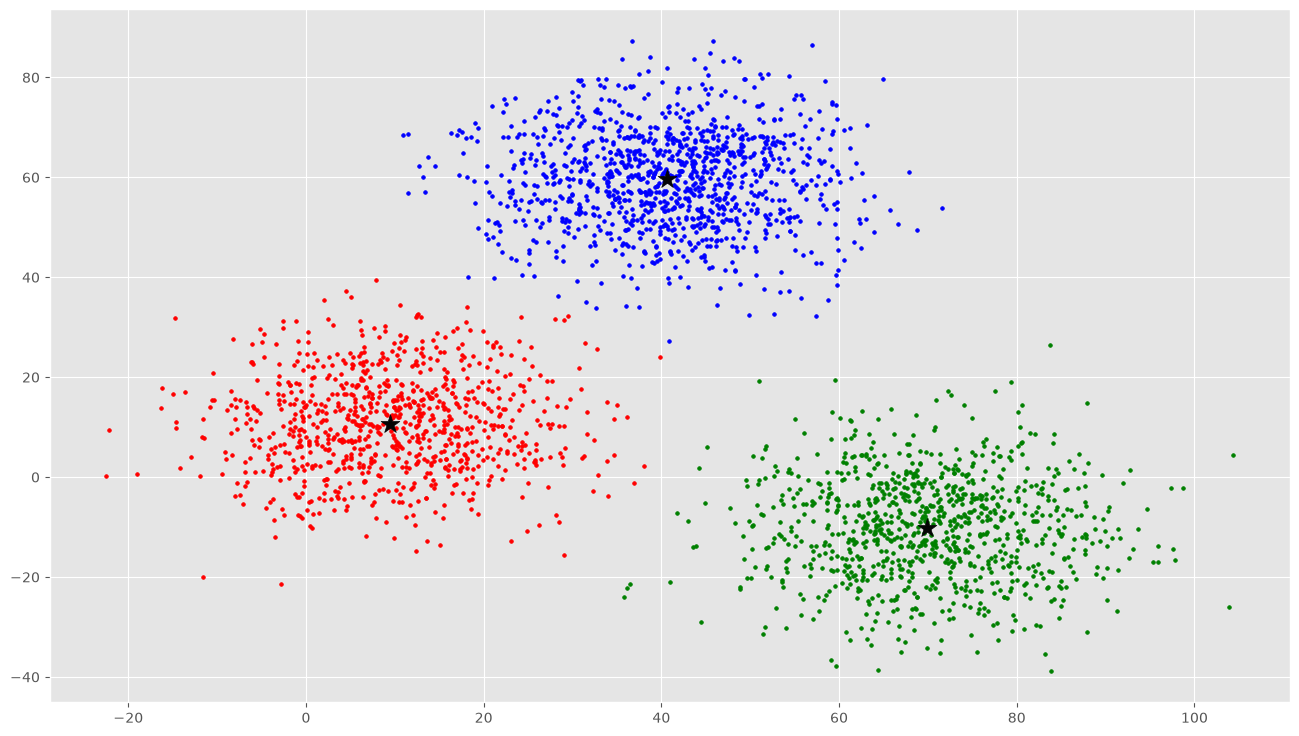

In [17]:
colors = ['r', 'g', 'b', 'y', 'c', 'm']

fig, ax = plt.subplots()
for i in range(k):
    points = np.array([X[j] for j in range(len(X)) if clusters[j] == i])
    ax.scatter(points[:, 0], points[:, 1], s=7, c=colors[i])
    
ax.scatter(C[:, 0], C[:, 1], marker='*', s=200, c='#050505')

In [19]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3)

kmeans = kmeans.fit(X)

labels = kmeans.predict(X)

centroids = kmeans.cluster_centers_

In [20]:
print(C)
print(centroids)

[[  9.478045  10.686052]
 [ 69.92419  -10.119641]
 [ 40.683628  59.715893]]
[[  9.4780459   10.686052  ]
 [ 69.92418447 -10.11964119]
 [ 40.68362784  59.71589274]]


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs

plt.rcParams['figure.figsize'] = (16, 9)

X, y = make_blobs(n_samples=800, n_features=3, centers=4)

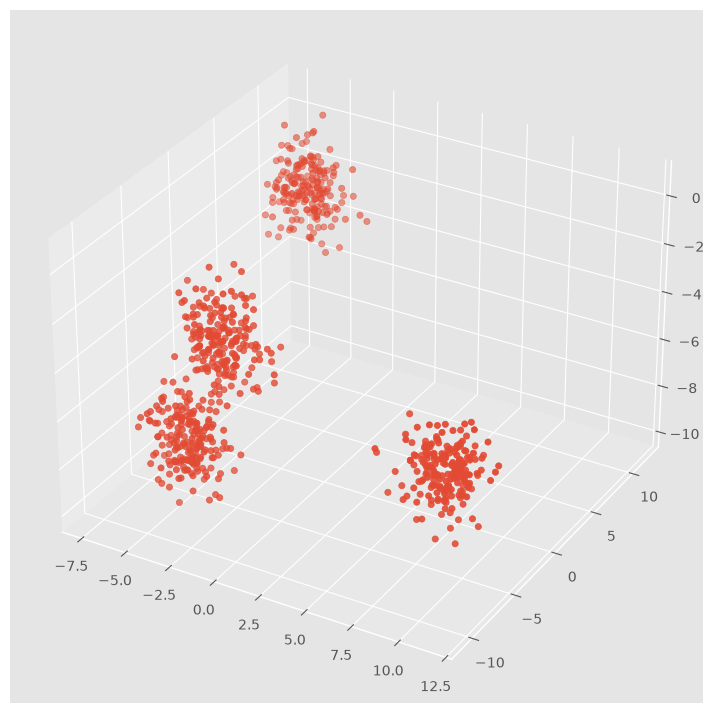

In [27]:
fig = plt.figure()
ax = fig.add_subplot(111, projection="3d")
ax.scatter(X[:, 0], X[:, 1], X[:, 2])
plt.show()

In [25]:
kmeans = KMeans(n_clusters=4)

kmeans = kmeans.fit(X)

labels = kmeans.predict(X)

C = kmeans.cluster_centers_

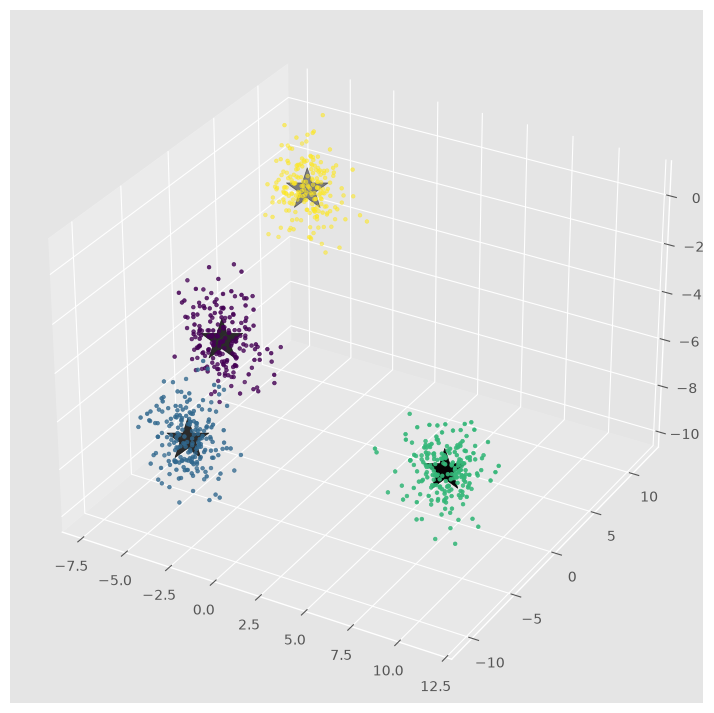

In [32]:
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

ax.scatter(
    X[:, 0], X[:, 1], X[:, 2],
    c=y,
    s=7
)

ax.scatter(
    C[:, 0], C[:, 1], C[:, 2],
    marker='*',
    c='#050505',
    s=1000
)

plt.show()